# Análise de Desempenho de E-commerce (UK Online Retail)

**Pergunta de negócio:** como se comportam as vendas e os clientes de uma loja online do Reino Unido (dez/2010 a dez/2011), e o que isso sugere para o time comercial?

**Base:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail). Veja `dataset/README.md` para baixar.

**Como ler este notebook:** cada seção termina com uma nota de **cuidado de interpretação**, porque os dados mostram *o que aconteceu*, não *por que aconteceu*.

Seções: 1. Carga e verificações · 2. Limpeza · 3. Visão geral · 4. Produtos e países · 5. Sazonalidade · 6. Retenção por coorte · 7. Segmentação RFM · 8. Hábitos dos clientes campeões · 9. Resumo

## 1. Carga e verificações

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Funciona tanto rodando de dentro de notebooks/ quanto da raiz do projeto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_DADOS = RAIZ / "dataset"

CANDIDATOS = ["retail_data.csv", "online_retail.xlsx", "Online_Retail.xlsx", "online_retail.csv"]
arquivo = next((PASTA_DADOS / n for n in CANDIDATOS if (PASTA_DADOS / n).exists()), None)
if arquivo is None:
    raise FileNotFoundError(
        f"Nenhum arquivo de dados em {PASTA_DADOS}. Baixe a base (veja dataset/README.md) "
        f"e salve como um destes nomes: {CANDIDATOS}"
    )
print("Lendo:", arquivo.name)

if arquivo.suffix == ".xlsx":
    bruto = pd.read_excel(arquivo)          # requer openpyxl
else:
    bruto = pd.read_csv(arquivo, dtype=str)  # tudo como texto: o tipo é decidido abaixo, de forma explícita

print(f"{len(bruto):,} linhas x {bruto.shape[1]} colunas")
bruto.head()

Lendo: retail_data.csv
541,909 linhas x 8 colunas


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,"2,55",17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,"3,39",17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,"2,75",17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,"3,39",17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,"3,39",17850,United Kingdom


In [3]:
COLUNAS = {"InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"}
faltando = COLUNAS - set(bruto.columns)
assert not faltando, f"Colunas ausentes: {faltando}"


def para_numero(serie):
    """Converte para número aceitando vírgula decimal ('2,55'), sem descartar dados em silêncio."""
    if pd.api.types.is_numeric_dtype(serie):
        return serie
    return pd.to_numeric(serie.astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")


df = bruto.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["Quantity"] = para_numero(df["Quantity"])
df["UnitPrice"] = para_numero(df["UnitPrice"])
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = para_numero(df["CustomerID"])

# --- Verificações que falham alto em vez de perder dados em silêncio ---
for col in ["Quantity", "UnitPrice", "InvoiceDate"]:
    perda = df[col].isna().mean()
    print(f"{col}: {perda:.2%} de valores inválidos após a conversão")
    assert perda < 0.01, (
        f"{col}: {perda:.1%} das linhas viraram nulo na conversão. "
        "Provável problema de formato (vírgula decimal, formato de data). Corrija antes de seguir."
    )

# A base original cobre 01/12/2010 a 09/12/2011. Datas fora disso indicam dia/mês trocados.
print("Período:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
assert df["InvoiceDate"].min() >= pd.Timestamp("2010-12-01") and df["InvoiceDate"].max() < pd.Timestamp("2011-12-10"), (
    "Período fora do esperado (01/12/2010 a 09/12/2011). Verifique se dia e mês estão invertidos na leitura da data."
)

C:\Users\muniz\AppData\Local\Temp\ipykernel_19772\1358774485.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")


Quantity: 0.00% de valores inválidos após a conversão
UnitPrice: 0.00% de valores inválidos após a conversão
InvoiceDate: 0.00% de valores inválidos após a conversão
Período: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


## 2. Limpeza
Cada regra é contada, para ficar claro quanto da base cada uma remove.

In [4]:
cancelada = df["InvoiceNo"].str.startswith("C")          # fatura de cancelamento/devolução
qtd_invalida = ~cancelada & (df["Quantity"] <= 0)         # ajustes de estoque etc.
preco_invalido = ~cancelada & (df["Quantity"] > 0) & (df["UnitPrice"] <= 0)

relatorio = pd.DataFrame(
    {
        "linhas": [len(df), cancelada.sum(), qtd_invalida.sum(), preco_invalido.sum()],
    },
    index=["Linhas na base", "Removidas: faturas canceladas (começam com C)",
           "Removidas: quantidade <= 0 (sem ser cancelamento)", "Removidas: preço unitário <= 0"],
)
relatorio["% da base"] = relatorio["linhas"] / len(df)
display(relatorio)

vendas = df[~cancelada & ~qtd_invalida & ~preco_invalido].copy()
vendas["ReceitaTotal"] = vendas["Quantity"] * vendas["UnitPrice"]
vendas["Mes"] = vendas["InvoiceDate"].dt.to_period("M")

# Linhas que não são produtos físicos (frete, taxas, ajustes manuais, vale-presente etc.).
# Os códigos de produto reais começam com 5 dígitos (ex.: 85123A); os demais são serviços/ajustes.
vendas["EhProduto"] = vendas["StockCode"].str.match(r"^\d{5}")
nao_produto = vendas.loc[~vendas["EhProduto"], "StockCode"].value_counts().head(10)
print("Códigos que NÃO são produto (mais frequentes):")
print(nao_produto.to_string())
print(f"\nReceita dessas linhas: {vendas.loc[~vendas['EhProduto'], 'ReceitaTotal'].sum():,.0f} "
      f"({vendas.loc[~vendas['EhProduto'], 'ReceitaTotal'].sum() / vendas['ReceitaTotal'].sum():.1%} do total)")

produtos = vendas[vendas["EhProduto"]]

,linhas,% da base
Linhas na base,541909,1.00
Removidas: faturas canceladas (começam com C),9288,0.02
Removidas: quantidade <= 0 (sem ser cancelamento),1336,0.00
Removidas: preço unitário <= 0,1181,0.00


Códigos que NÃO são produto (mais frequentes):
StockCode
POST            1126
DOT              706
M                321
C2               141
DCGSSGIRL         13
BANK CHARGES      12
DCGSSBOY          11
gift_0001_20       9
gift_0001_10       8
gift_0001_30       7

Receita dessas linhas: 395,650 (3.7% do total)


**Cuidado de interpretação.** Cancelamentos foram removidos, então a receita aqui é *receita bruta de vendas*, sem devoluções.
Isso pode superestimar o valor de clientes que devolvem muito. Se a pergunta fosse lucratividade, essa decisão precisaria ser revista.

## 3. Visão geral

In [5]:
ids_validos = vendas["CustomerID"].notna()
resumo_geral = {
    "Receita total (£)": vendas["ReceitaTotal"].sum(),
    "Faturas": vendas["InvoiceNo"].nunique(),
    "Clientes identificados": vendas.loc[ids_validos, "CustomerID"].nunique(),
    "% da receita sem CustomerID": vendas.loc[~ids_validos, "ReceitaTotal"].sum() / vendas["ReceitaTotal"].sum(),
    "Ticket médio por fatura (£)": vendas.groupby("InvoiceNo")["ReceitaTotal"].sum().mean(),
}
pd.Series(resumo_geral).to_frame("valor")

,valor
Receita total (£),"10,666,684.54"
Faturas,"19,960.00"
Clientes identificados,"4,338.00"
% da receita sem CustomerID,0.16
Ticket médio por fatura (£),534.40


**Cuidado de interpretação.** Uma parte da receita não tem `CustomerID`. Ela entra nas análises de produto, país e sazonalidade,
mas **não** entra em coortes nem em RFM, que precisam identificar o cliente.

## 4. Produtos e países

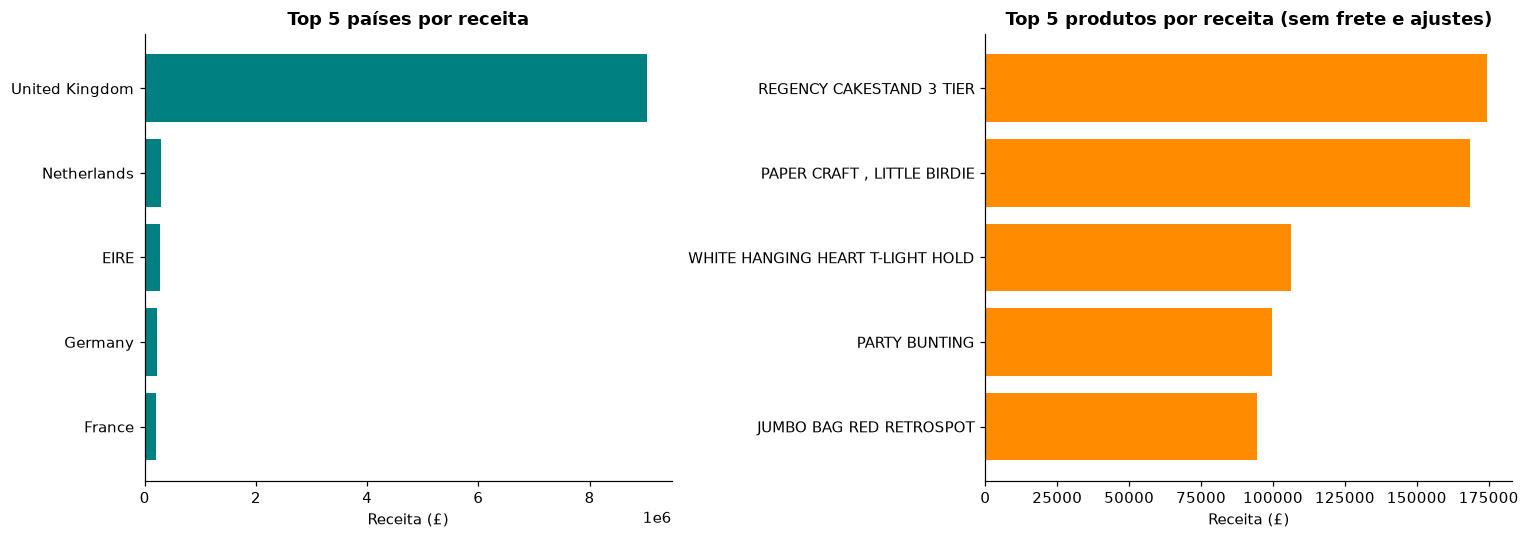

,Receita (£)
Description,
REGENCY CAKESTAND 3 TIER,"174,484.74"
"PAPER CRAFT , LITTLE BIRDIE","168,469.60"
WHITE HANGING HEART T-LIGHT HOLDER,"106,292.77"
PARTY BUNTING,"99,504.33"
JUMBO BAG RED RETROSPOT,"94,340.05"


In [6]:
def barras_h(serie, titulo, cor, rotulo_x="Receita (£)", ax=None):
    ax = ax or plt.gca()
    serie = serie.sort_values()
    ax.barh([str(i)[:32] for i in serie.index], serie.values, color=cor)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel(rotulo_x)


top_produtos = produtos.groupby("Description")["ReceitaTotal"].sum().nlargest(5)
top_paises = vendas.groupby("Country")["ReceitaTotal"].sum().nlargest(5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
barras_h(top_paises, "Top 5 países por receita", "teal", ax=ax1)
barras_h(top_produtos, "Top 5 produtos por receita (sem frete e ajustes)", "darkorange", ax=ax2)
plt.tight_layout()
plt.show()

top_produtos.to_frame("Receita (£)")

In [7]:
# Quanto cada país representa e como é o comportamento de compra deles
paises = vendas.groupby("Country").agg(
    receita=("ReceitaTotal", "sum"),
    faturas=("InvoiceNo", "nunique"),
    clientes=("CustomerID", "nunique"),
).assign(
    pct_receita=lambda d: d["receita"] / d["receita"].sum(),
    ticket_fatura=lambda d: d["receita"] / d["faturas"],
).sort_values("receita", ascending=False)

paises.head(8)

,receita,faturas,clientes,pct_receita,ticket_fatura
Country,,,,,
United Kingdom,"9,025,222.08",18019,3920,0.85,500.87
Netherlands,"285,446.34",94,9,0.03,"3,036.66"
EIRE,"283,453.96",288,3,0.03,984.22
Germany,"228,867.14",457,94,0.02,500.80
France,"209,715.11",392,87,0.02,534.99
Australia,"138,521.31",57,9,0.01,"2,430.20"
Spain,"61,577.11",90,30,0.01,684.19
Switzerland,"57,089.90",54,21,0.01,"1,057.22"


**Cuidado de interpretação.** O Reino Unido concentra a maior parte da receita. Países como Alemanha, França ou Irlanda terem muita venda
mostra que **já compram**, mas não mostra que **estão crescendo** nem que há espaço para expandir. Para falar de oportunidade seria preciso
ver a evolução por país ao longo do tempo (seção 5) e, de preferência, comparar com o tamanho do mercado. Trate expansão como **hipótese a testar**.

## 5. Sazonalidade

Última data: 09/12/2011. Último mês parcial (excluído das comparações).
Mês de maior receita (entre os completos): 2011-11 = £1,509,496


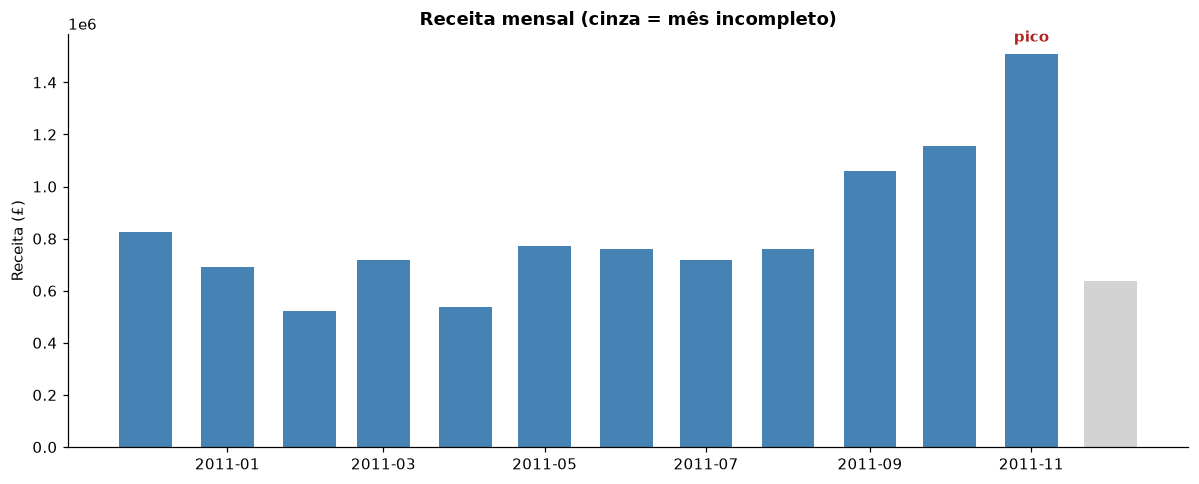

In [8]:
ultimo = vendas["InvoiceDate"].max()
ultimo_mes = ultimo.to_period("M")
mes_parcial = (ultimo + pd.Timedelta(days=1)).month == ultimo.month   # o último mês termina antes do fim?
ultimo_mes_completo = ultimo_mes - 1 if mes_parcial else ultimo_mes
print(f"Última data: {ultimo:%d/%m/%Y}. Último mês {'parcial (excluído das comparações)' if mes_parcial else 'completo'}.")

mensal = vendas.groupby("Mes")["ReceitaTotal"].sum().to_frame("receita")
mensal["completo"] = mensal.index <= ultimo_mes_completo
completos = mensal[mensal["completo"]]

pico_mes = completos["receita"].idxmax()
print(f"Mês de maior receita (entre os completos): {pico_mes} = £{completos.loc[pico_mes, 'receita']:,.0f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
x = mensal.index.to_timestamp()
ax.bar(x, mensal["receita"], width=20, color=np.where(mensal["completo"], "steelblue", "lightgray"))
ax.set_title("Receita mensal (cinza = mês incompleto)", fontweight="bold")
ax.set_ylabel("Receita (£)")
ax.annotate("pico", xy=(pico_mes.to_timestamp(), completos.loc[pico_mes, "receita"]),
            xytext=(0, 8), textcoords="offset points", ha="center", color="firebrick", fontweight="bold")
plt.tight_layout()
plt.show()

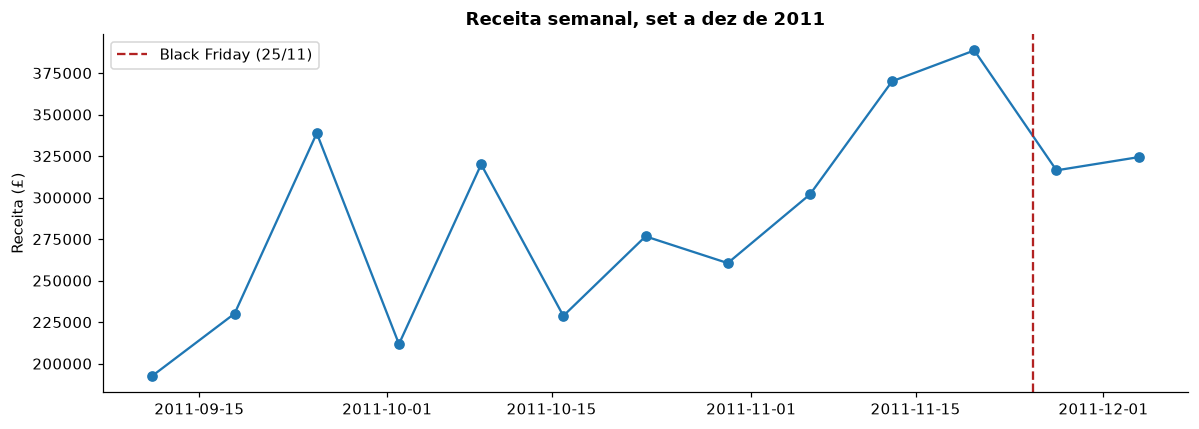

In [9]:
# O pico é "Black Friday" ou a temporada de fim de ano como um todo? Olhamos semana a semana.
ano_pico = pico_mes.year
quintas = pd.date_range(f"{ano_pico}-11-01", f"{ano_pico}-11-30", freq="W-THU")
black_friday = quintas[3] + pd.Timedelta(days=1)      # sexta após o 4º Thanksgiving (4ª quinta de novembro)

inicio_janela = pd.Timestamp(f"{ano_pico}-09-01")
semanal = (vendas[(vendas["InvoiceDate"] >= inicio_janela) & (vendas["InvoiceDate"] <= ultimo)]
           .set_index("InvoiceDate")["ReceitaTotal"].resample("W-SUN").sum())
# descarta semanas incompletas nas pontas (começo da janela e fim da base), que distorceriam a curva
semanal = semanal[(semanal.index - pd.Timedelta(days=6) >= inicio_janela) & (semanal.index <= ultimo.normalize())]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(semanal.index, semanal.values, marker="o")
ax.axvline(black_friday, color="firebrick", linestyle="--", label=f"Black Friday ({black_friday:%d/%m})")
ax.set_title(f"Receita semanal, set a dez de {ano_pico}", fontweight="bold")
ax.set_ylabel("Receita (£)")
ax.legend()
plt.tight_layout()
plt.show()

**Cuidado de interpretação.**
- A base tem **um único ano** de dados (13 meses), então há **um** novembro completo. Isso mostra um padrão nesse ano, não prova que a sazonalidade se repete.
- Se a receita já vem subindo semanas antes da linha vermelha, o pico **não se explica só pela Black Friday**: a temporada de Natal é uma explicação concorrente e os dados sozinhos não separam as duas.
- Escreva como hipótese ("o pico coincide com a Black Friday e a temporada de fim de ano"), não como causa.

## 6. Retenção por coorte
Coorte = mês da primeira compra de cada cliente identificado. A tabela mostra que % deles voltou a comprar nos meses seguintes.

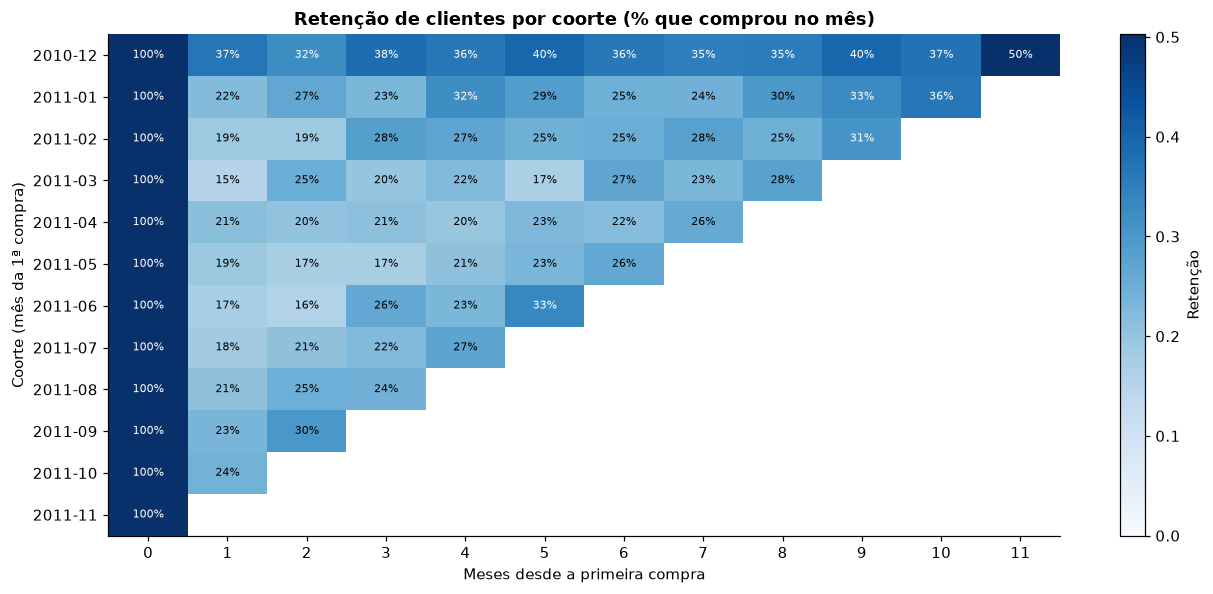

Retenção média por mês desde a 1ª compra (média simples entre coortes com dado):
Indice
1    21.5%
2    23.2%
3    24.6%
4    26.1%
5    27.1%
6    26.8%

Clientes com 2 ou mais compras: 64.2%


In [10]:
cli = vendas[vendas["CustomerID"].notna() & (vendas["Mes"] <= ultimo_mes_completo)].copy()
cli["Coorte"] = cli.groupby("CustomerID")["Mes"].transform("min")
cli["Indice"] = (cli["Mes"] - cli["Coorte"]).apply(lambda d: d.n)

ativos = cli.groupby(["Coorte", "Indice"])["CustomerID"].nunique().unstack(fill_value=0)
retencao = ativos.div(ativos[0], axis=0)

# Só mostra células observáveis: coorte c só tem dados até o último mês completo
for coorte in retencao.index:
    max_idx = (ultimo_mes_completo - coorte).n
    retencao.loc[coorte, retencao.columns > max_idx] = np.nan

fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(retencao.values, cmap="Blues", vmin=0, vmax=np.nanmax(retencao.drop(columns=0).values), aspect="auto")
ax.set_xticks(range(retencao.shape[1]), retencao.columns)
ax.set_yticks(range(retencao.shape[0]), [str(c) for c in retencao.index])
ax.set_xlabel("Meses desde a primeira compra")
ax.set_ylabel("Coorte (mês da 1ª compra)")
ax.set_title("Retenção de clientes por coorte (% que comprou no mês)", fontweight="bold")
for i in range(retencao.shape[0]):
    for j in range(retencao.shape[1]):
        v = retencao.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 * np.nanmax(retencao.drop(columns=0).values) else "black")
fig.colorbar(im, ax=ax, label="Retenção")
plt.tight_layout()
plt.show()

tamanho = ativos[0].rename("clientes na coorte")
retencao_media = retencao.drop(columns=0).mean()
print("Retenção média por mês desde a 1ª compra (média simples entre coortes com dado):")
print(retencao_media.head(6).map("{:.1%}".format).to_string())

n_pedidos = cli.groupby("CustomerID")["InvoiceNo"].nunique()
print(f"\nClientes com 2 ou mais compras: {(n_pedidos >= 2).mean():.1%}")

**Cuidado de interpretação.**
- A base começa em dez/2010, então a **coorte de dez/2010 mistura clientes novos com clientes antigos**: não sabemos qual foi a primeira compra *de verdade*. Ela tende a mostrar retenção maior e deve ser lida com ressalva.
- Coortes recentes têm menos meses observados (as células vazias), e coortes pequenas dão porcentagens instáveis. Veja `tamanho` antes de comparar.
- Mede *comprar de novo*, não *satisfação*: um cliente pode ficar sem comprar por motivos que a base não registra.

In [11]:
tamanho.to_frame()

,clientes na coorte
Coorte,
2010-12,885
2011-01,417
2011-02,380
2011-03,452
2011-04,300
2011-05,284
2011-06,242
2011-07,188
2011-08,169


## 7. Segmentação RFM
Pontuação de 1 a 5 em **R**ecência (dias desde a última compra), **F**requência (nº de faturas) e **M**onetário (receita), por quintis.

In [12]:
data_ref = ultimo + pd.Timedelta(days=1)   # "hoje" = dia seguinte à última data da base

clientes = vendas[vendas["CustomerID"].notna()]
rfm = clientes.groupby("CustomerID").agg(
    Recencia=("InvoiceDate", lambda s: (data_ref - s.max()).days),
    Frequencia=("InvoiceNo", "nunique"),
    Monetario=("ReceitaTotal", "sum"),
)

# rank(method="first") evita erro de quintis quando muitos clientes empatam (ex.: Frequencia = 1)
rfm["R"] = pd.qcut(rfm["Recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)  # menos dias = melhor
rfm["F"] = pd.qcut(rfm["Frequencia"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetario"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

regras = [
    (rfm["R"].ge(4) & rfm["F"].ge(4) & rfm["M"].ge(4), "Campeões"),
    (rfm["R"].le(2) & rfm["F"].ge(4) & rfm["M"].ge(4), "Em risco (bons clientes que sumiram)"),
    (rfm["F"].ge(4) & rfm["M"].ge(4), "Fiéis"),
    (rfm["R"].ge(4) & rfm["F"].le(2), "Novos / recentes"),
]
rfm["Segmento"] = np.select([c for c, _ in regras], [n for _, n in regras], default="Demais")

seg = rfm.groupby("Segmento").agg(
    clientes=("Monetario", "size"),
    receita=("Monetario", "sum"),
    recencia_media_dias=("Recencia", "mean"),
    frequencia_media=("Frequencia", "mean"),
).assign(
    pct_clientes=lambda d: d["clientes"] / d["clientes"].sum(),
    pct_receita=lambda d: d["receita"] / d["receita"].sum(),
).sort_values("receita", ascending=False)
seg

,clientes,receita,recencia_media_dias,frequencia_media,pct_clientes,pct_receita
Segmento,,,,,,
Campeões,947,"5,755,513.22",12.54,11.15,0.22,0.65
Demais,2665,"1,867,924.76",131.59,1.90,0.61,0.21
Fiéis,243,"754,691.41",48.66,6.42,0.06,0.08
Em risco (bons clientes que sumiram),173,"390,109.94",123.80,5.52,0.04,0.04
Novos / recentes,310,"143,168.57",18.10,1.25,0.07,0.02


**Cuidado de interpretação.** Os cortes (quintis, nota ≥ 4) são uma **convenção**, não uma lei: mudar o corte muda quem é "campeão".
A análise descreve o comportamento passado (13 meses) e não diz o que funcionaria para reter esses clientes. Um programa de fidelidade é uma **ideia a testar**, por exemplo com um grupo de controle.

## 8. O que os clientes campeões compram

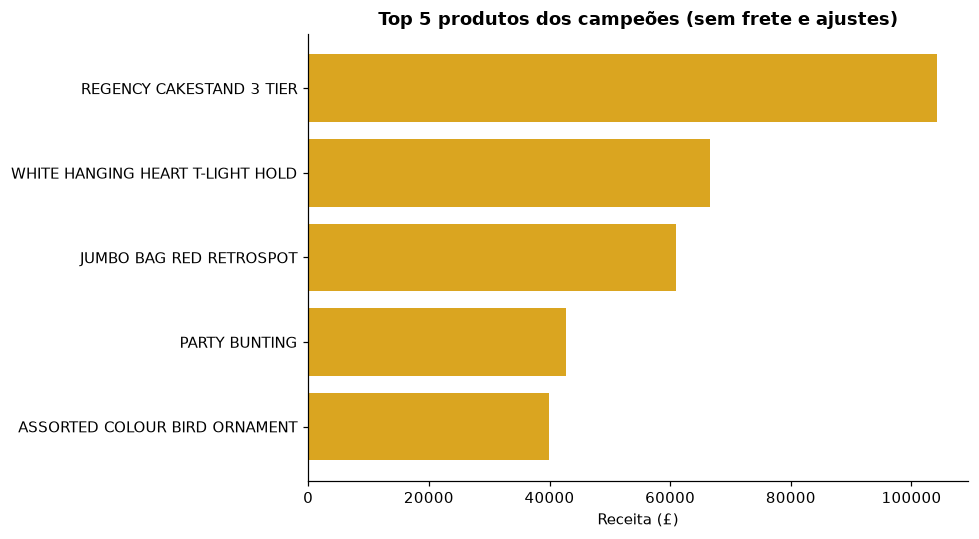

,receita,clientes
Description,,
REGENCY CAKESTAND 3 TIER,"104,159.85",317
WHITE HANGING HEART T-LIGHT HOLDER,"66,637.30",311
JUMBO BAG RED RETROSPOT,"60,945.25",306
PARTY BUNTING,"42,732.93",280
ASSORTED COLOUR BIRD ORNAMENT,"39,909.33",266
RABBIT NIGHT LIGHT,"37,246.07",244
CHILLI LIGHTS,"36,357.55",96
BLACK RECORD COVER FRAME,"31,755.11",64
PAPER CHAIN KIT 50'S CHRISTMAS,"31,411.83",267


In [13]:
ids_campeoes = rfm.index[rfm["Segmento"] == "Campeões"]
compras = produtos[produtos["CustomerID"].isin(ids_campeoes)]   # 'produtos' já exclui frete, taxas e ajustes

top_campeoes = compras.groupby("Description").agg(
    receita=("ReceitaTotal", "sum"),
    clientes=("CustomerID", "nunique"),
).sort_values("receita", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5))
barras_h(top_campeoes["receita"].head(5), "Top 5 produtos dos campeões (sem frete e ajustes)", "goldenrod", ax=ax)
plt.tight_layout()
plt.show()

top_campeoes

**Cuidado de interpretação.** O que os campeões **mais compram em valor** pode ser só o que a loja mais vende no geral. Para dizer que é uma *preferência do grupo*,
compare a participação de cada produto entre os campeões e entre os demais clientes. Campanhas de recomendação ou pacotes (*bundles*) com esses itens são hipóteses a testar.

## 9. Resumo dos achados
Números calculados acima, prontos para copiar para o README.

In [14]:
campeoes = seg.loc["Campeões"] if "Campeões" in seg.index else None
resumo = {
    "Período analisado": f"{vendas['InvoiceDate'].min():%d/%m/%Y} a {ultimo:%d/%m/%Y}",
    "Linhas após a limpeza": f"{len(vendas):,}",
    "Receita total (£)": f"{vendas['ReceitaTotal'].sum():,.0f}",
    "Clientes identificados": f"{vendas['CustomerID'].nunique():,}",
    "Participação do 1º país": f"{paises.index[0]} = {paises['pct_receita'].iloc[0]:.1%} da receita",
    "Mês de maior receita (completo)": str(pico_mes),
    "Retenção média no mês 1": f"{retencao_media.get(1, float('nan')):.1%}",
    "Clientes com 2+ compras": f"{(n_pedidos >= 2).mean():.1%}",
}
if campeoes is not None:
    resumo["Campeões"] = (f"{int(campeoes['clientes']):,} clientes ({campeoes['pct_clientes']:.1%}) "
                          f"= {campeoes['pct_receita']:.1%} da receita")
for k, v in resumo.items():
    print(f"{k:34s} {v}")

Período analisado                  01/12/2010 a 09/12/2011
Linhas após a limpeza              530,104
Receita total (£)                  10,666,685
Clientes identificados             4,338
Participação do 1º país            United Kingdom = 84.6% da receita
Mês de maior receita (completo)    2011-11
Retenção média no mês 1            21.5%
Clientes com 2+ compras            64.2%
Campeões                           947 clientes (21.8%) = 64.6% da receita
